In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [7]:
df = pd.read_csv(r"C:\Users\mm com\Downloads\Student_Marks.csv")
print("Shape:", df.shape)
df.head()


Shape: (100, 3)


,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


In [8]:
df.head()

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


In [9]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isnull().sum())


Data types:

number_courses      int64
time_study        float64
Marks             float64
dtype: object

Missing values per column:

number_courses    0
time_study        0
Marks             0
dtype: int64


In [10]:
df.describe()

,number_courses,time_study,Marks
count,100.000000,100.000000,100.000000
mean,5.290000,4.077140,24.417690
std,1.799523,2.372914,14.326199
min,3.000000,0.096000,5.609000
25%,4.000000,2.058500,12.633000
50%,5.000000,4.022000,20.059500
75%,7.000000,6.179250,36.676250
max,8.000000,7.957000,55.299000


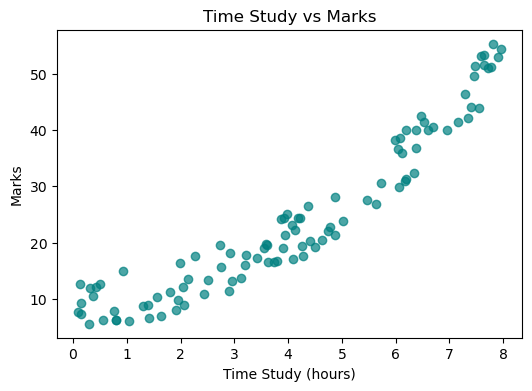

In [11]:
plt.figure(figsize=(6,4))
plt.scatter(df["time_study"], df["Marks"], alpha=0.7, color="teal")
plt.xlabel("Time Study (hours)")
plt.ylabel("Marks")
plt.title("Time Study vs Marks")
plt.show()


In [12]:
X = df[["number_courses", "time_study"]]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (80, 2)  Test shape: (20, 2)


In [13]:
linear_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])

print("Pipelines created.")


Pipelines created.


In [14]:
linear_pipeline.fit(X_train, y_train)
poly_pipeline.fit(X_train, y_train)
print("Both models trained.")


Both models trained.


In [15]:
pred_linear = linear_pipeline.predict(X_test)
pred_poly = poly_pipeline.predict(X_test)

mae_linear = mean_absolute_error(y_test, pred_linear)
r2_linear = r2_score(y_test, pred_linear)

mae_poly = mean_absolute_error(y_test, pred_poly)
r2_poly = r2_score(y_test, pred_poly)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (deg=2)"],
    "MAE": [mae_linear, mae_poly],
    "R2 Score": [r2_linear, r2_poly]
})
results


,Model,MAE,R2 Score
0,Linear Regression,3.079345,0.945994
1,Polynomial Regression (deg=2),0.227760,0.999691


In [16]:
print(f"Linear Regression      -> MAE: {mae_linear:.4f} | R2: {r2_linear:.4f}")
print(f"Polynomial Regression   -> MAE: {mae_poly:.4f} | R2: {r2_poly:.4f}")

better_model_name = "Linear Regression" if r2_linear >= r2_poly else "Polynomial Regression (deg=2)"
best_pipeline = linear_pipeline if r2_linear >= r2_poly else poly_pipeline
print(f"\nBetter performing model: {better_model_name}")


Linear Regression      -> MAE: 3.0793 | R2: 0.9460
Polynomial Regression   -> MAE: 0.2278 | R2: 0.9997

Better performing model: Polynomial Regression (deg=2)


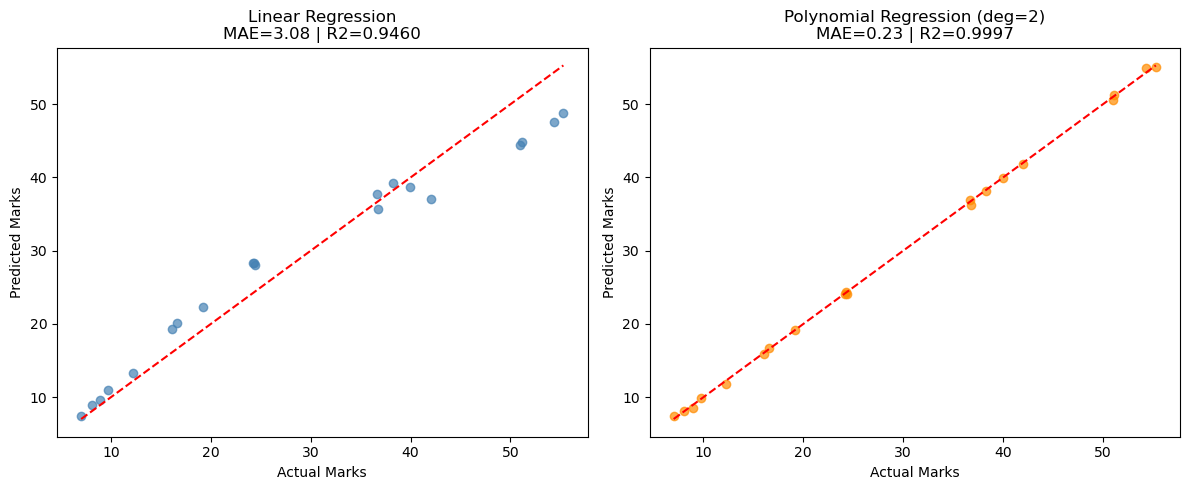

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred_linear, alpha=0.7, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title(f"Linear Regression\nMAE={mae_linear:.2f} | R2={r2_linear:.4f}")
axes[0].set_xlabel("Actual Marks")
axes[0].set_ylabel("Predicted Marks")

axes[1].scatter(y_test, pred_poly, alpha=0.7, color="darkorange")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Polynomial Regression (deg=2)\nMAE={mae_poly:.2f} | R2={r2_poly:.4f}")
axes[1].set_xlabel("Actual Marks")
axes[1].set_ylabel("Predicted Marks")

plt.tight_layout()
plt.show()


In [18]:
def predict_marks(number_courses, time_study):
    """
    Predict a student's marks from raw input values using the trained pipeline
    (scaling + polynomial expansion + model are applied automatically).
    """
    input_df = pd.DataFrame([{
        "number_courses": number_courses,
        "time_study": time_study
    }])
    predicted_marks = best_pipeline.predict(input_df)[0]
    return predicted_marks

print("Predictive function ready.")


Predictive function ready.


In [19]:
example_marks = predict_marks(number_courses=5, time_study=6.5)
print(f"Predicted marks for the example student: {example_marks:.2f}")


Predicted marks for the example student: 37.33
